In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from scipy.stats import chi2_contingency

from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif

In [8]:
# Leemos el dataset
df = pd.read_csv(
    'Crimes_-_2015_20260905.csv',
    parse_dates=['Date', 'Updated On'],
    date_format={
        'Date': '%m/%d/%Y %I:%M:%S %p',
        'Updated On': "%Y %b %d %I:%M:%S %p",
    },
)

df.head()

,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,...,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
0,10365064,HZ100370,2015-12-31 23:59:00,075XX S EMERALD AVE,1320,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,...,17.0,68.0,14,1172605.0,1854931.0,2015,2018-02-10 15:50:01,41.757367,-87.642993,POINT (-87.642992854 41.757366519)
1,10460641,HZ199559,2015-12-31 23:59:00,015XX N KEDZIE AVE,0890,THEFT,FROM BUILDING,RESIDENCE PORCH/HALLWAY,False,False,...,26.0,23.0,06,NaN,NaN,2015,2018-02-09 15:44:29,NaN,NaN,NaN
2,10364662,HZ100006,2015-12-31 23:55:00,079XX S STONY ISLAND AVE,0430,BATTERY,AGGRAVATED: OTHER DANG WEAPON,STREET,False,False,...,8.0,45.0,04B,1188223.0,1852840.0,2015,2018-02-10 15:50:01,41.751270,-87.585822,POINT (-87.585822373 41.751270452)
3,10364740,HZ100010,2015-12-31 23:50:00,024XX W FARGO AVE,0820,THEFT,$500 AND UNDER,APARTMENT,False,False,...,50.0,2.0,06,1158878.0,1949369.0,2015,2018-02-10 15:50:01,42.016804,-87.690709,POINT (-87.690708662 42.016804165)
4,10364683,HZ100002,2015-12-31 23:50:00,037XX N CLARK ST,0460,BATTERY,SIMPLE,SIDEWALK,True,False,...,44.0,6.0,08B,1167786.0,1925033.0,2015,2018-02-10 15:50:01,41.949837,-87.658635,POINT (-87.658635101 41.949837364)


In [9]:
# Algunos crímenes aparecen más de una vez en el dataset, asi que los identificamos a través del Case Number
df_unique = df.drop_duplicates('Case Number')

# Definimos nuestra variable objectivo
y = df_unique['Arrest']

# Eliminamos las variables redundantes para dejar solo los features
X = df_unique.drop([
    # Variable objetivo
    'Arrest',
    
    # Identificadores
    'ID',
    'Case Number',

    # Fue asignado posterior al hecho
    'Updated On',

    # Tiene el mismo valor para todas las filas
    'Year',

    # Redundantes con respecto a X Coordinate y Y Coordinate
    'Latitude',
    'Longitude',
    'Location',
], axis=1)

X.head()

,Date,Block,IUCR,Primary Type,Description,Location Description,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate
0,2015-12-31 23:59:00,075XX S EMERALD AVE,1320,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,621,6,17.0,68.0,14,1172605.0,1854931.0
1,2015-12-31 23:59:00,015XX N KEDZIE AVE,0890,THEFT,FROM BUILDING,RESIDENCE PORCH/HALLWAY,False,1422,14,26.0,23.0,06,NaN,NaN
2,2015-12-31 23:55:00,079XX S STONY ISLAND AVE,0430,BATTERY,AGGRAVATED: OTHER DANG WEAPON,STREET,False,411,4,8.0,45.0,04B,1188223.0,1852840.0
3,2015-12-31 23:50:00,024XX W FARGO AVE,0820,THEFT,$500 AND UNDER,APARTMENT,False,2411,24,50.0,2.0,06,1158878.0,1949369.0
4,2015-12-31 23:50:00,037XX N CLARK ST,0460,BATTERY,SIMPLE,SIDEWALK,False,1923,19,44.0,6.0,08B,1167786.0,1925033.0


In [10]:
# Realizamos los splits de train y test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    # Dado que la variable target tiene un desbalance, se estratifica para que train
    # y test mantengan las proporciones
    stratify=y,
)

print(str(len(X_train.index))+' filas de train')
print(str(len(X_test.index))+' filas de test')

# Verificamos que se mantuvo la proporcio2n de arresto
print(pd.DataFrame({
    'total': y.value_counts(normalize=True),
    'train': y_train.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True),
}).round(2))

211906 filas de train
52977 filas de test
        total  train  test
Arrest                    
False    0.74   0.74  0.74
True     0.26   0.26  0.26


### Ubicación geográfica

Al agrupar las variables Beat, District, Ward y Community Area, podemos ver que corresponden a la ubicación geográfica donde se reportó el crimen.

In [11]:
# Las coordenadas se pueden escalar a un rango entre 0 y 1
scaler = MinMaxScaler()
X_train[['X Coordinate', 'Y Coordinate']] = scaler.fit_transform(X_train[['X Coordinate', 'Y Coordinate']])

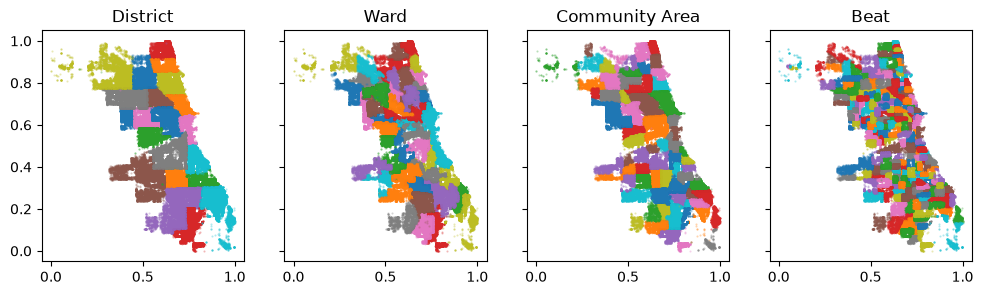

In [12]:
def plot_region(a, X_filtered):
    a.scatter(X_filtered["X Coordinate"], X_filtered["Y Coordinate"], s=0.3, alpha=0.3)

region_columns = ['District', 'Ward', 'Community Area', 'Beat']

# Dividimos el gráfico en partes
fig, axs = plt.subplots(1, 4, figsize=(12, 3))

# Iteramos por cada columna a graficar
for i, column in enumerate(region_columns):
    a = axs[i]
    a.set_title(column)

    # Graficamos cada valor único con un color diferente
    X_train.groupby(column, sort=False).apply(lambda X_filtered: plot_region(a, X_filtered))

# Ocultamos las etiquetas entre gráficos
for ax in axs.flat:
    ax.label_outer()

Como la columna Beat tiene la granularidad más pequeña y no tiene ningún valor faltante, podemos utilizarla para imputar las coordenadas faltantes.

In [13]:
# Realizamos una copia del dataframe
X_train_fillna = X_train.copy()

# Sobrescribimos las columnas con el promedio de cada grupo
X_train_fillna['X Coordinate'] = X_train.groupby('Beat')['X Coordinate'].transform(lambda column: column.fillna(column.mean()))
X_train_fillna['Y Coordinate'] = X_train.groupby('Beat')['Y Coordinate'].transform(lambda column: column.fillna(column.mean()))

# Para las variables categórias, utilizamos la moda
X_train_fillna['Ward'] = X_train.groupby('Beat')['Ward'].transform(lambda column: column.fillna(column.mode()[0]))
X_train_fillna['Community Area'] = X_train.groupby('Beat')['Community Area'].transform(lambda column: column.fillna(column.mode()[0]))

# Solo la columna Location Description queda con valores nulos
X_train_fillna.isna().sum()

Date                      0
Block                     0
IUCR                      0
Primary Type              0
Description               0
Location Description    477
Domestic                  0
Beat                      0
District                  0
Ward                      0
Community Area            0
FBI Code                  0
X Coordinate              0
Y Coordinate              0
dtype: int64

Para comparar la relevancia entre las variables geográficas, podemos discretizar las coordenadas. Probamos diferentes niveles de granularidad.

In [14]:
discrete_coordinate_columns = []

# Probamos con diferentes números de bins
for sqrt_bins in [10, 15, 20, 30]:
    bins = sqrt_bins*sqrt_bins
    discrete_x_coordinates = pd.cut(X_train_fillna['X Coordinate'], bins=sqrt_bins, labels=False)
    discrete_y_coordinates = pd.cut(X_train_fillna['Y Coordinate'], bins=sqrt_bins, labels=False)

    # Combinamos ambas coordenadas en una sola variable categórica
    column_name = str(bins)+' Bins'
    X_train_fillna[column_name] = discrete_y_coordinates * sqrt_bins + discrete_x_coordinates
    discrete_coordinate_columns.append(column_name)

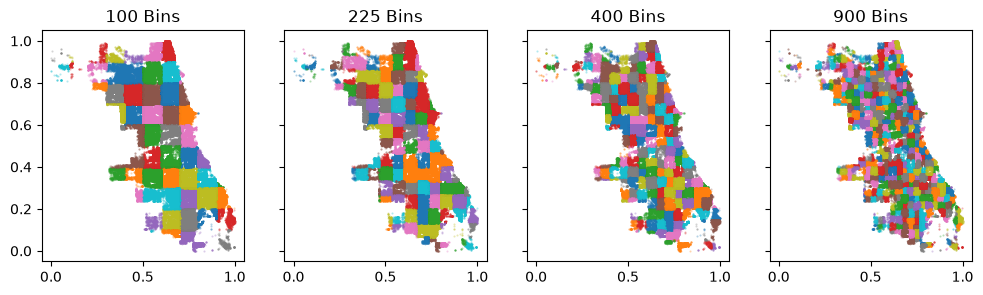

In [15]:
# Dividimos el gráfico en partes
fig, axs = plt.subplots(1, 4, figsize=(12, 3))

# Iteramos por cada columna a graficar
for i, column in enumerate(discrete_coordinate_columns):
    a = axs[i]
    a.set_title(column)

    # Graficamos cada valor único con un color diferente
    X_train_fillna.groupby(column, sort=False).apply(lambda X_filtered: plot_region(a, X_filtered))

# Ocultamos las etiquetas entre gráficos
for ax in axs.flat:
    ax.label_outer()

Utiizamos Cramér's V para observar el nivel de correlación entre las variables categóricas. Como es de esperarse, el nivel de correlación es bastante alto.

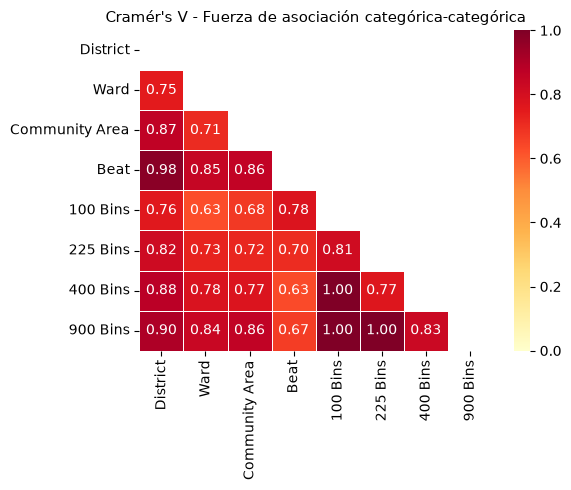

In [16]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    return np.sqrt(chi2 / (n * min(k - 1, r - 1)))

cat_cols = region_columns+discrete_coordinate_columns

v_mat = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)

# Utilizamos un slice para mostrar solo la mitad inferior de la matriz
for i, c1 in enumerate(cat_cols):
    for c2 in cat_cols[:i]:
        v_mat.loc[c1, c2] = cramers_v(X_train_fillna[c1], X_train_fillna[c2])

# Dibujamos la matriz con heatmap
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(v_mat.astype(float), annot=True, fmt=".2f", cmap="YlOrRd",
            vmin=0, vmax=1, linewidths=0.5, ax=ax)

ax.set_title("Cramér's V - Fuerza de asociación categórica-categórica", fontsize=11)
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

Calculamos la información mutua para decidir cuál de todas conservar. Las variables con mayor cardinalidad resultan ser más releventas para el problema.

In [17]:
pd.DataFrame(
    {'Mutual Information': mutual_info_classif(X_train_fillna[cat_cols], y_train, discrete_features=True)},
    index = cat_cols,
).sort_values('Mutual Information', ascending=False)

,Mutual Information
900 Bins,0.026356
Beat,0.025492
400 Bins,0.022234
225 Bins,0.019619
Community Area,0.018506
100 Bins,0.017112
Ward,0.016058
District,0.015589


### Tipo de crimen

Observando la correlación Cramér's V, podemos ver que las variables IUCR, FBI Code, y Primary Type se encuentran fuertemente relacionadas. Esto es de esperarse, ya que todas ellas describen el tipo de crimen.

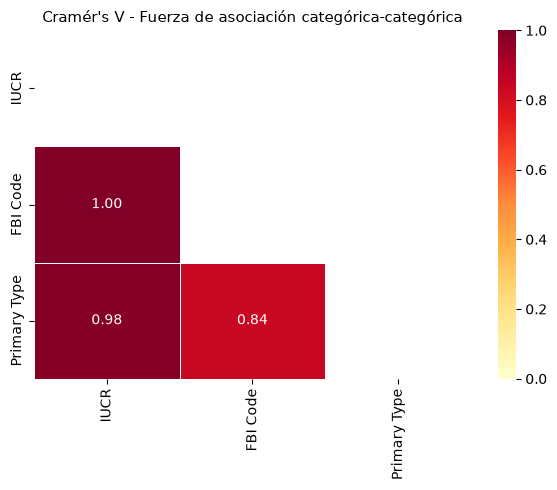

In [18]:
cat_cols = ['IUCR', 'FBI Code', 'Primary Type']

v_mat = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)

# Utilizamos un slice para mostrar solo la mitad inferior de la matriz
for i, c1 in enumerate(cat_cols):
    for c2 in cat_cols[:i]:
        v_mat.loc[c1, c2] = cramers_v(X_train[c1], X_train[c2])

# Dibujamos la matriz con heatmap
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(v_mat.astype(float), annot=True, fmt=".2f", cmap="YlOrRd",
            vmin=0, vmax=1, linewidths=0.5, ax=ax)

ax.set_title("Cramér's V - Fuerza de asociación categórica-categórica", fontsize=11)
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

In [19]:
# Antes de medir la información mutua, es necesario codificar cada una de estas varibles
iucr_encoder = LabelEncoder()
fbi_code__encoder = LabelEncoder()
primary_type_encoder = LabelEncoder()

X_train_fillna['IUCR'] = iucr_encoder.fit_transform(X_train_fillna['IUCR'])
X_train_fillna['FBI Code'] = iucr_encoder.fit_transform(X_train_fillna['FBI Code'])
X_train_fillna['Primary Type'] = iucr_encoder.fit_transform(X_train_fillna['Primary Type'])

Al medir la información mutua, vemos que la variable IUCR es la que presenta más relevancia con respecto a la variable objetivo.

In [20]:
pd.DataFrame(
    {'Mutual Information': mutual_info_classif(X_train_fillna[cat_cols], y_train, discrete_features=True)},
    index = cat_cols,
).sort_values('Mutual Information', ascending=False)

,Mutual Information
IUCR,0.280932
Primary Type,0.211044
FBI Code,0.209335
